In [1]:
%load_ext autoreload
%autoreload 2

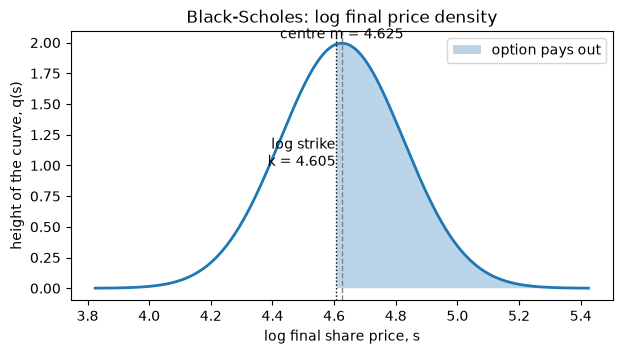

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pricing import centre_and_spread, log_price_density

S0, r, T, vol, K = 100, 0.04, 1.0, 0.20, 100

# 1. Work out where the curve sits, so the plot covers it
m, spread = centre_and_spread(S0, r, T, vol)
s = np.linspace(m - 4 * spread, m + 4 * spread, 500)

# 2. Height of the bell curve at each log price
q = log_price_density(s, S0, r, T, vol)

# 3. Plot it
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(s, q, lw=2)

# 4. Shade the part above the log strike: where the option pays out
k = np.log(K)
ax.fill_between(s, q, where=(s > k), alpha=0.3, label="option pays out")

# 5. Mark the centre and the strike
ax.axvline(m, ls="--", color="grey", lw=1)
ax.axvline(k, ls=":", color="black", lw=1)
ax.text(m, q.max() * 1.02, f"centre m = {m:.3f}", ha="center")
ax.text(k, q.max() * 0.5, f"log strike\nk = {k:.3f}", ha="right")

ax.set_xlabel("log final share price, s")
ax.set_ylabel("height of the curve, q(s)")
ax.set_title("Black-Scholes: log final price density")
ax.legend()
plt.show()

In [3]:
from pricing import price_by_average

price_by_average(100, 100, 0.04, 1.0, 0.20)

np.float64(9.925053717274436)

In [4]:
from pricing import fingerprint_bs
import numpy as np


F = fingerprint_bs(1, 100, 0.04, 1.0, 0.20)
print(abs(F), np.angle(F) % (2 * np.pi))

0.9801986733067553 4.625170185988091


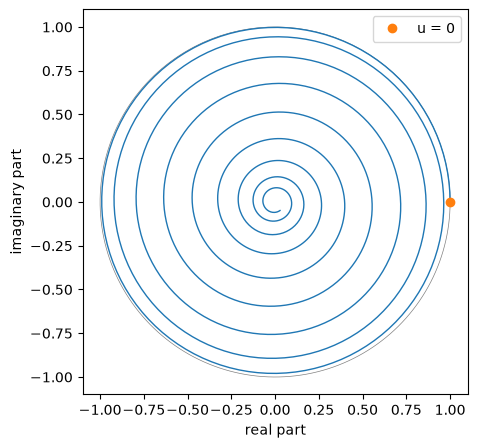

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pricing import fingerprint_bs

u = np.linspace(0, 12, 1000)
F = fingerprint_bs(u, 100, 0.04, 1.0, 0.20)

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color="grey", lw=0.5)  # circle of radius 1
ax.plot(F.real, F.imag, lw=1)                                # path of the arrow's tip
ax.plot(1, 0, "o", label="u = 0")
ax.set_aspect("equal")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.legend()
plt.show()

## outcomes arrows spin around the origin, shrinking as the spin increases, this is the fourier transform of log-price distribution

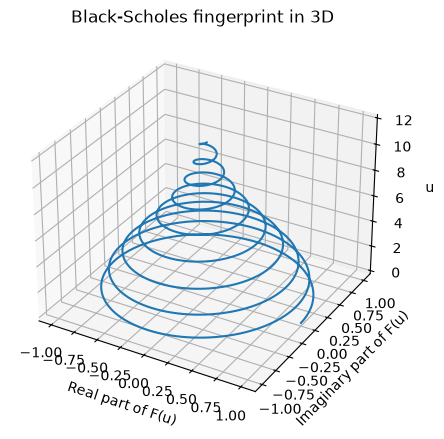

In [6]:
## with u as a third dimension

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot(F.real, F.imag, u, lw=1.5)
ax.set_xlabel("Real part of F(u)")
ax.set_ylabel("Imaginary part of F(u)")
ax.set_zlabel("u")
ax.set_title("Black-Scholes fingerprint in 3D")

plt.show()

In [7]:
from pricing import bs_price, damped_price

for K in [0.0001, 1, 100]:
    print(K, bs_price(100, K, 0.04, 1.0, 0.20), damped_price(100, K, 0.04, 1.0, 0.20))

0.0001 99.99990392105609 9.99999039210561e-05
1 99.03921056084768 99.03921056084768
100 9.925053717274437 9925.053717274437


In [8]:
from pricing import wound_up

wound_up(2.0, 100, 0.04, 1.0, 0.20)

np.complex128(74.94335225999684+13200.101047459502j)

total by rows:    30520.876495299693
total by columns: 30520.876495299693
wound_up(0):      30520.980916035027


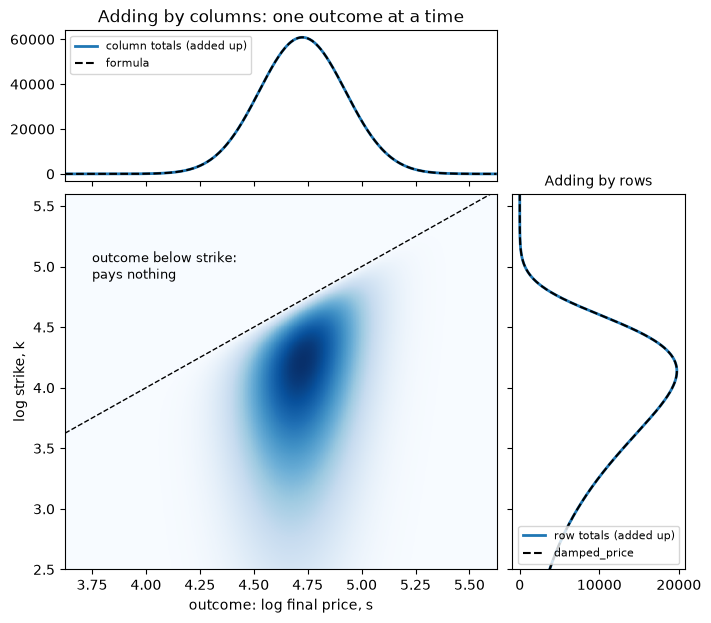

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pricing import log_price_density, damped_price, centre_and_spread, wound_up

S0, r, T, vol, a = 100, 0.04, 1.0, 0.20, 1.5
m, spread = centre_and_spread(S0, r, T, vol)

# The table: outcomes (log final price, s) across, log strikes (k) down
s = np.linspace(m - 5 * spread, m + 5 * spread, 600)
k = np.linspace(-10, 6, 4000)
S, K = np.meshgrid(s, k)

# Each cell: discount x chance of the outcome x damping x payoff
cells = (np.exp(-r * T) * log_price_density(S, S0, r, T, vol)
         * np.exp(a * K) * np.maximum(np.exp(S) - np.exp(K), 0))

# Way 1: add along each row -> the damped price at each strike
row_totals = np.trapezoid(cells, s, axis=1)

# Way 2: add down each column -> one outcome's contribution
col_totals = np.trapezoid(cells, k, axis=0)

# What each should match
row_formula = np.array([damped_price(S0, np.exp(kk), r, T, vol, a) for kk in k])
col_formula = (np.exp(-r * T) * log_price_density(s, S0, r, T, vol)
               * np.exp((a + 1) * s) / (a ** 2 + a))

print("total by rows:   ", np.trapezoid(row_totals, k))
print("total by columns:", np.trapezoid(col_totals, s))
print("wound_up(0):     ", wound_up(0, S0, r, T, vol, a).real)

# The figure: table in the middle, column totals on top, row totals on the right
fig = plt.figure(figsize=(8, 7))
grid = fig.add_gridspec(2, 2, width_ratios=[3, 1.2], height_ratios=[1.2, 3],
                        wspace=0.05, hspace=0.05)
ax = fig.add_subplot(grid[1, 0])
top = fig.add_subplot(grid[0, 0], sharex=ax)
right = fig.add_subplot(grid[1, 1], sharey=ax)

ax.pcolormesh(s, k, cells, shading="auto", cmap="Blues")
ax.plot(s, s, color="black", lw=1, ls="--")
ax.text(3.75, 4.9, "outcome below strike:\npays nothing", fontsize=9)
ax.set_xlabel("outcome: log final price, s")
ax.set_ylabel("log strike, k")
ax.set_ylim(2.5, 5.6)

top.plot(s, col_totals, lw=2, label="column totals (added up)")
top.plot(s, col_formula, ls="--", color="black", label="formula")
top.legend(fontsize=8)
top.set_title("Adding by columns: one outcome at a time")
plt.setp(top.get_xticklabels(), visible=False)

right.plot(row_totals, k, lw=2, label="row totals (added up)")
right.plot(row_formula, k, ls="--", color="black", label="damped_price")
right.legend(fontsize=8, loc="lower right")
right.set_title("Adding by rows", fontsize=10)
plt.setp(right.get_yticklabels(), visible=False)

plt.show()

In [10]:
from pricing import price_one_strike, bs_price

for K in [80, 100, 120]:
    print(K, price_one_strike(100, K, 0.04, 1.0, 0.20), bs_price(100, K, 0.04, 1.0, 0.20))

80 23.90616366520407 23.906163665204048
100 9.925053717274409 9.925053717274437
120 2.9999485151236156 2.9999485151236236


In [14]:
from pricing import price_one_strike_grid

for K in [80, 90, 100, 110, 120]:
    print(K, price_one_strike_grid(100, K, 0.04, 1.0, 0.2), bs_price(100, K, 0.04, 1.0, 0.2))

80 23.906163665204076 23.906163665204048
90 16.06042801448809 16.060428014488096
100 9.925053717274409 9.925053717274437
110 5.65879247154633 5.658792471546349
120 2.9999485151236214 2.9999485151236236


In [15]:
np.fft.fft([1, 2, 3, 4])

array([10.+0.j, -2.+2.j, -2.+0.j, -2.-2.j])

In [18]:
N = 4096
spin_spacing = 0.25
strike_spacing = 2 * np.pi / (N * spin_spacing)   ## the grid rule

v = spin_spacing * np.arange(N)                  ## spin speeds 0, 0.25, 0.5, ...
k_start = np.log(100) - N * strike_spacing / 2   ## start half the list below ln 100
k = k_start + strike_spacing * np.arange(N)      ## log strikes, evenly spaced


print(strike_spacing)
print(v[-1])
print(k_start)
print(np.exp(k[2048]))
print(np.exp(k[2049]))


slices = np.exp(-1j * v * k_start) * wound_up(v, 100, 0.04, 1.0, 0.2) * spin_spacing
slices[0] = slices[0] / 2                      ## trapezium rule: the first edge counts half
totals = np.fft.fft(slices).real               ## the sum for every strike at once
prices = np.exp(-1.5 * k) / np.pi * totals     ## same ending as price_one_strike

0.006135923151542565
1023.75
-7.961200428371081
100.00000000000004
100.61547864895996


In [19]:
strikes, prices = price_all_strikes(100, 0.04, 1.0, 0.2)
near = (strikes > 80) & (strikes < 120)
print(np.max(np.abs(prices[near] - bs_price(100, strikes[near], 0.04, 1.0, 0.2))))

2.1707986874730523e-07
